# Support Vector Machines and Kernels

![SVM.png](Assets/SVM.png)

# Цели обучения
- Применить метод опорных векторов (SVM) — популярный алгоритм, используемый для задач классификации
- Распознать сходство SVM с логистической регрессией
- Вычислить функцию потерь для SVM
- Применить регуляризацию в SVM и изучить советы по получению нелинейной классификации с помощью SVM

## Введение
В этих упражнениях мы будем использовать набор данных о качестве вина. Этот набор данных содержит различные химические свойства вина, такие как кислотность, сахар, pH и алкоголь. Он также содержит метрику качества (от 3 до 9, где наивысший балл означает лучшее качество) и цвет (красное или белое). Имя файла: `Wine_Quality_Data.csv`.

In [1]:
from __future__ import print_function
import os
data_path = [ 'data']

from sklearn.svm import LinearSVC
from sklearn.svm import SVC
from sklearn.kernel_approximation import Nystroem
from sklearn.svm import SVC
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import MinMaxScaler

from sklearnex import patch_sklearn
patch_sklearn()

Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1
* Импорт данных.
* Создайте целевую переменную `y` как колонка 1/0, где 1 означает красное вино.
* Создайте парный график для набора данных.
* Создайте диаграмму столбцов, которая отображает корреляцию между каждым колонкой и `y`.
* Выберите 2 поля с наибольшей корреляцией (используя значения абсолютной корреляции) и создайте `X`.
* Используйте MinMaxScaler для масштабирования `X` Обратите внимание, что вывод будет np.array. Сделайте его снова DataFrame и соответственно переименуйте столбцы.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# в ячейке выше data_path = ['data'], но данные лежат в папке datasets
data_path = ['..', '..', '..', 'datasets']
filepath = os.sep.join(data_path + ['Wine_Quality_Data.csv'])
data = pd.read_csv(filepath)

# 1, если вино красное, и 0, если белое
y = (data['color'] == 'red').astype(int)
print(data.shape)
y.value_counts()

(6497, 13)


color
0    4898
1    1599
Name: count, dtype: int64

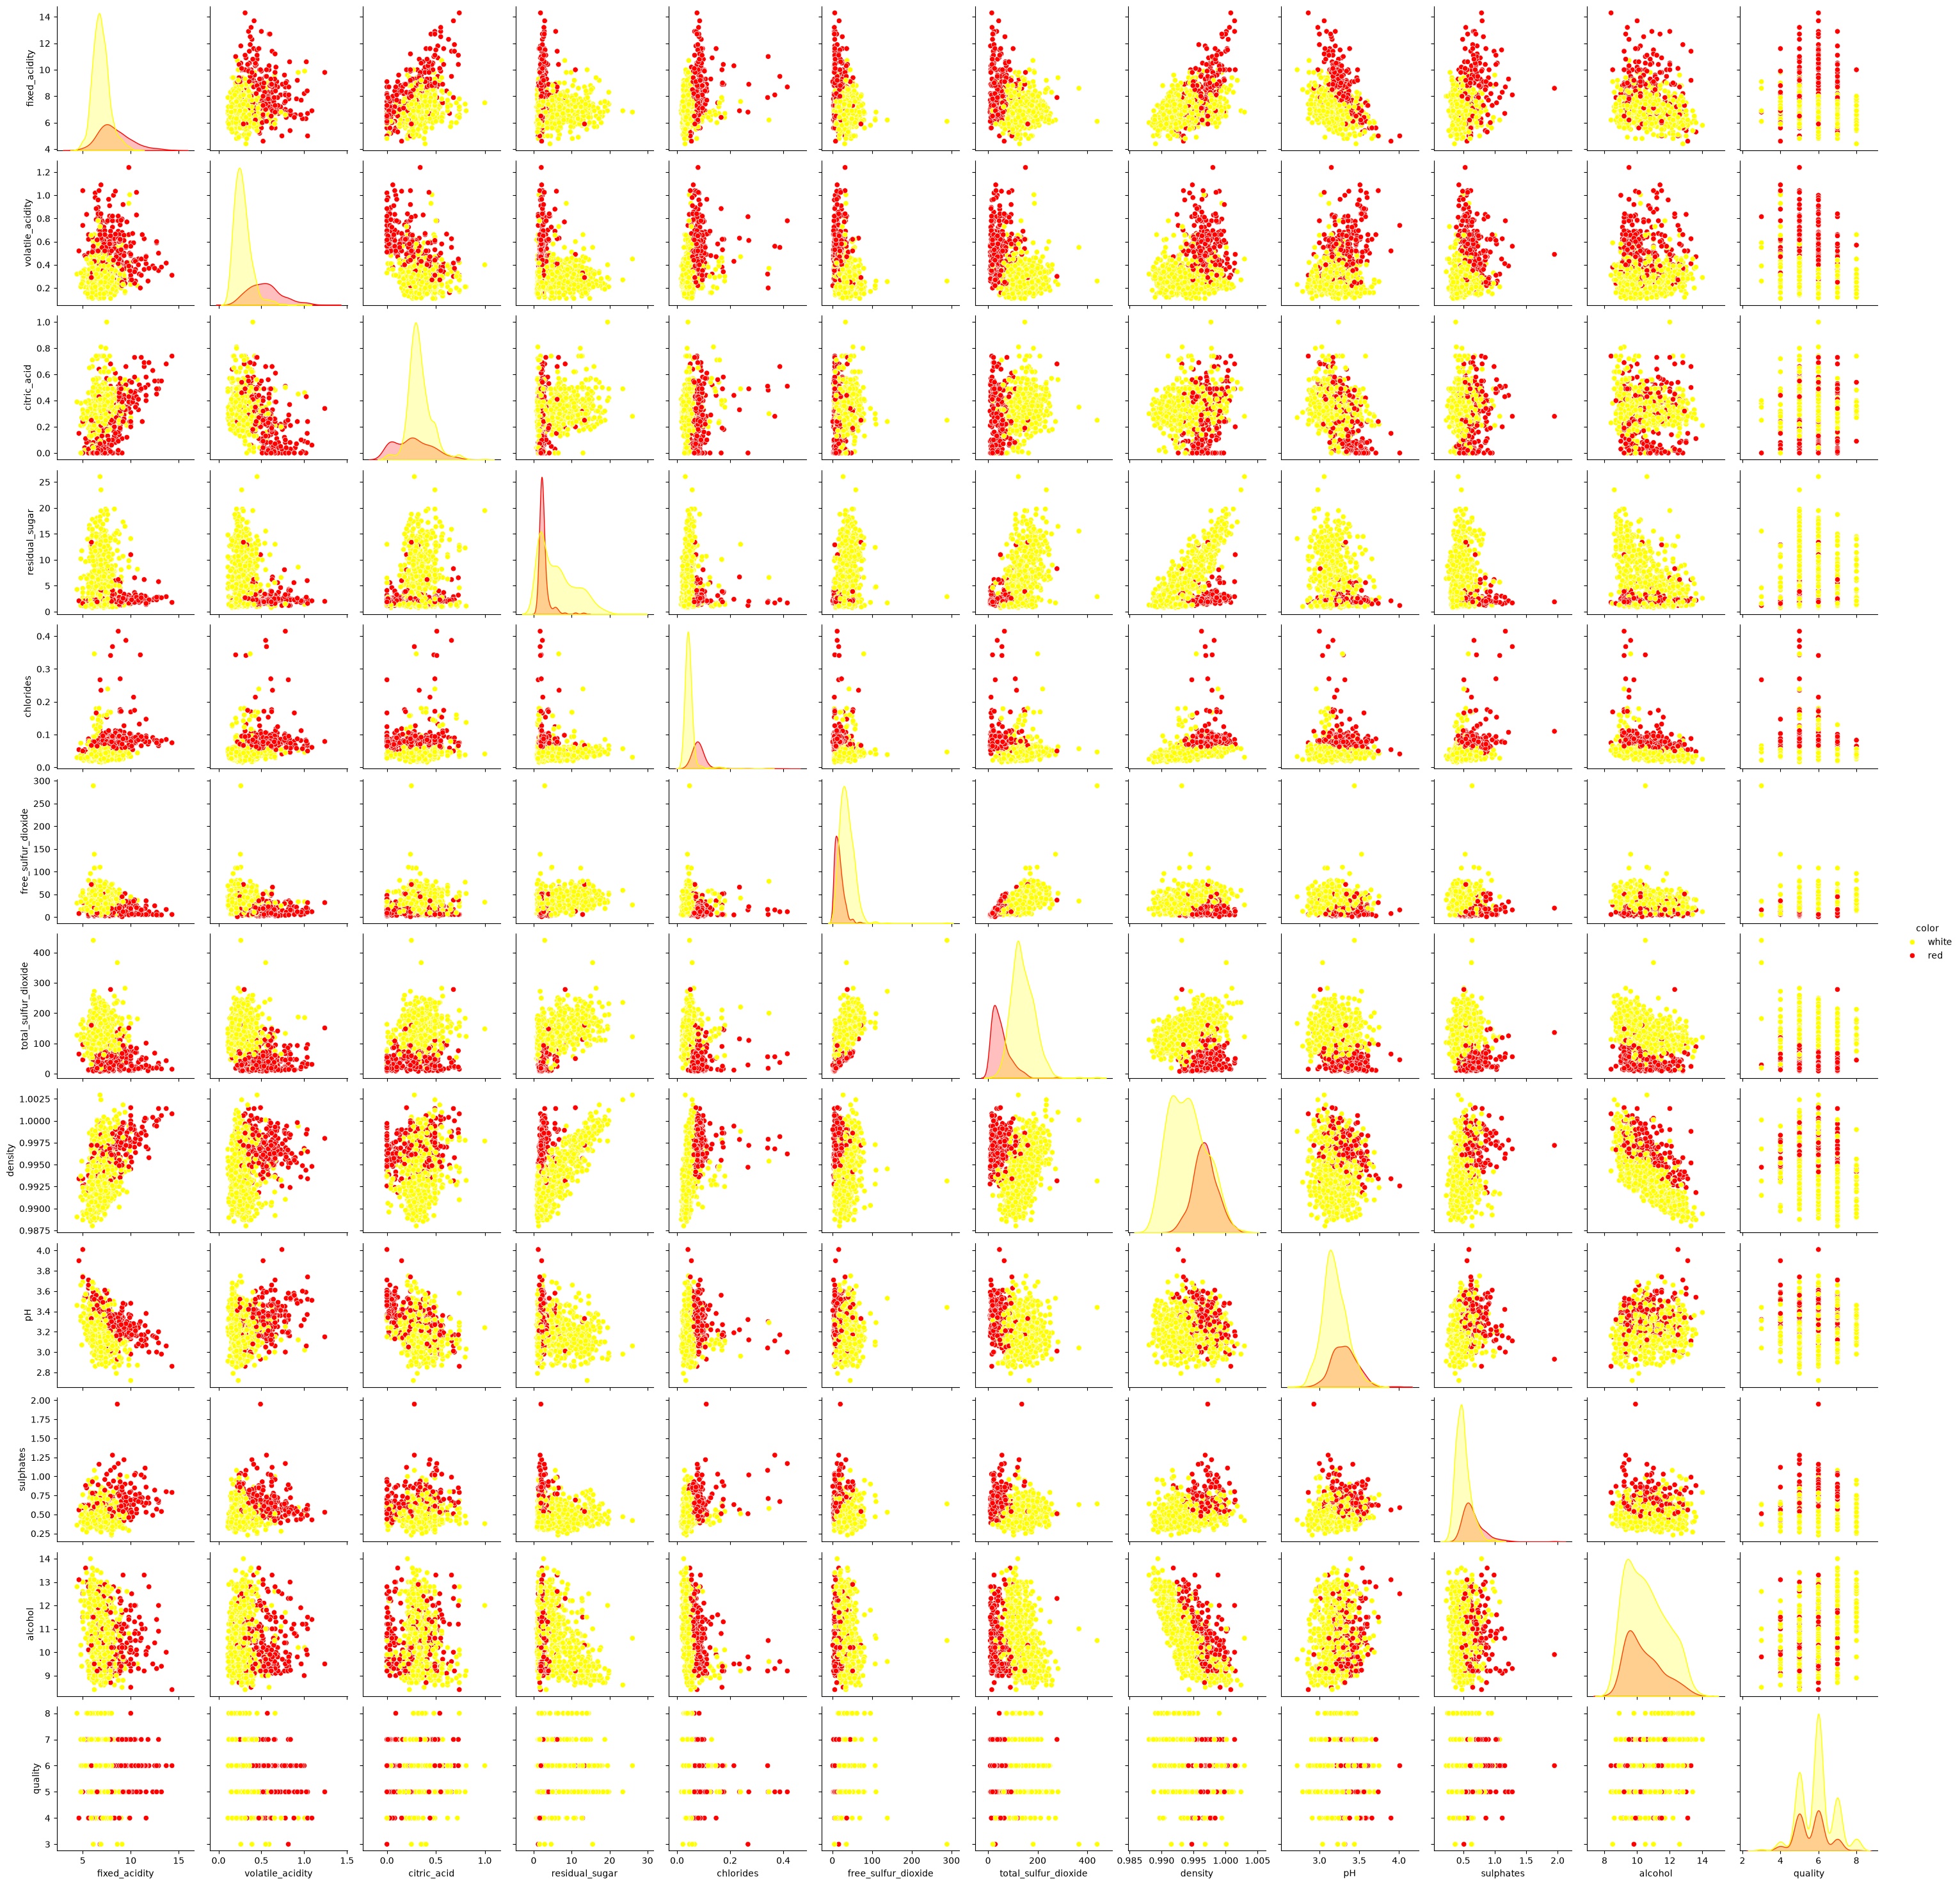

In [3]:
# на всех 6497 строках точки сливаются и график строится долго, поэтому берем случайные 1000
sns.pairplot(
    data.sample(1000, random_state=42),
    hue='color',
    palette={'red': 'red', 'white': 'yellow'},
    # plot_kws={'alpha': 0.2}
);

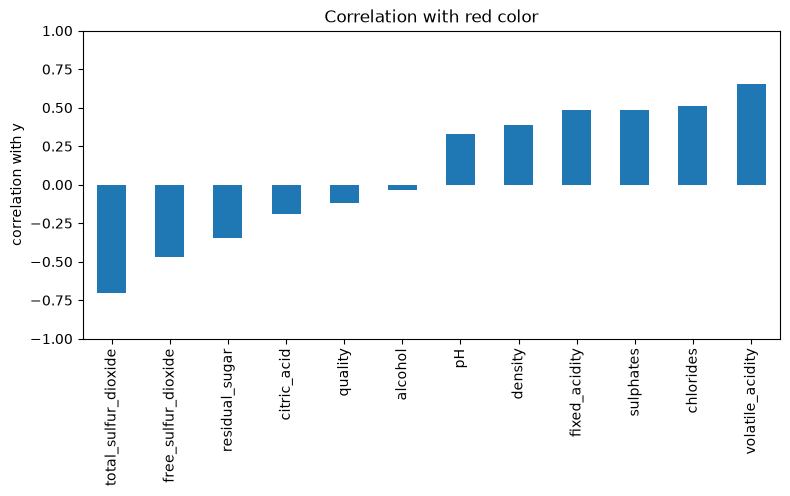

In [4]:
fields = [c for c in data.columns if c != 'color']
correlations = data[fields].corrwith(y).sort_values()

ax = correlations.plot(kind='bar', figsize=(9, 4))
ax.set(ylim=[-1, 1], ylabel='correlation with y', title='Correlation with red color');

# сильнее всего с цветом связаны total_sulfur_dioxide (-0.70) и volatile_acidity (0.65):
# у красных вин меньше диоксида серы и больше летучих кислот

In [5]:
# два признака с самой большой корреляцией по модулю
top2 = correlations.abs().sort_values().index[-2:]
print(list(top2))

scaler = MinMaxScaler()
X = scaler.fit_transform(data[top2])
# fit_transform возвращает np.array, поэтому снова делаем DataFrame и называем колонки
X = pd.DataFrame(X, columns=[c + '_scaled' for c in top2])
X.head()

['volatile_acidity', 'total_sulfur_dioxide']


,volatile_acidity_scaled,total_sulfur_dioxide_scaled
0,0.413333,0.064516
1,0.533333,0.140553
2,0.453333,0.110599
3,0.133333,0.124424
4,0.413333,0.064516


## Вопрос 2

Цель этого вопроса - посмотреть на границу принятия решения классификатора LinearSVC для данного набора данных. Ознакомьтесь с [этим примером](http://scikit-learn.org/stable/auto_examples/svm/plot_iris.html#sphx-glr-auto-examples-svm-plot-iris-py) в документации sklearn. 

* Установите классификатор линейной векторной машины поддержки на `X` , `y`.
* Выберите 300 образцов из `X`. Получите соответствующее значение `y`. Сохраните их в переменных `X_color` и `y_color`. Это связано с тем, что оригинальный набор данных слишком велик и создает переполненный график.
* Измените `y_color` таким образом, чтобы вместо 1 было указано значение «красный», а вместо 0 - «желтый».
* Рассеянный график для столбцов X_color. Используйте аргумент ключевого слова "color=y_color" для отображения кода цвета.
* Используйте фрагмент кода ниже, чтобы нарисовать поверхность решения в цветной форме.

`python
x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)
xx, yy = np.meshgrid(x_axis, y_axis)
xx_ravel = xx.ravel()
yy_ravel = yy.ravel()
X_grid = pd.DataFrame([xx_ravel, yy_ravel]). T
y_grid_predictions = *[ВАША МОДЕЛЬ]*. predict(X_grid)
y_grid_predictions = y_grid_predictions.reshape(xx.shape)
ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)
`

Не стесняйтесь экспериментировать с различными вариантами параметров для LinearSVC и просмотреть границы принятия решения.

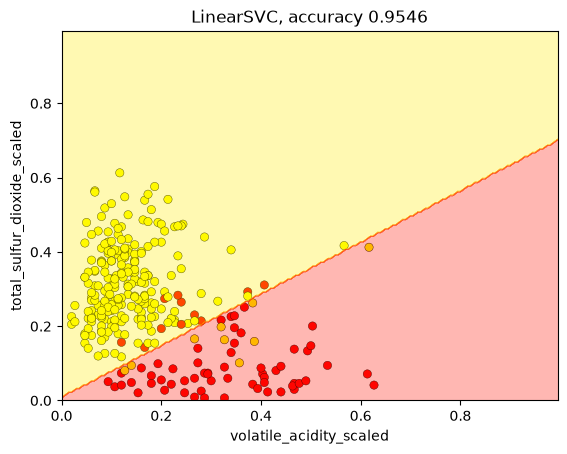

In [6]:
lsvc = LinearSVC()
lsvc.fit(X, y)

# 300 случайных точек для графика, иначе все сливается
X_color = X.sample(300, random_state=42)
y_color = y.loc[X_color.index]
y_color = y_color.map({1: 'red', 0: 'yellow'})

ax = plt.axes()
ax.scatter(X_color.iloc[:, 0], X_color.iloc[:, 1], color=y_color, alpha=1, edgecolor='k', linewidth=0.3)

# код из условия: предсказываем класс для каждой точки сетки и закрашиваем области
x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)
xx, yy = np.meshgrid(x_axis, y_axis)
xx_ravel = xx.ravel()
yy_ravel = yy.ravel()
X_grid = pd.DataFrame([xx_ravel, yy_ravel]).T
# названия колонок как у X, иначе sklearn выдает предупреждение
X_grid.columns = X.columns
y_grid_predictions = lsvc.predict(X_grid)
y_grid_predictions = y_grid_predictions.reshape(xx.shape)
ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)

ax.set(xlabel=X.columns[0], ylabel=X.columns[1],
       title='LinearSVC, accuracy ' + str(round(lsvc.score(X, y), 4)));

# LinearSVC делит плоскость прямой линией: выше нее белые вина, у них больше total_sulfur_dioxide, ниже красные.
# Около линии точки двух классов перемешаны, поэтому даже на train accuracy примерно 0.955, а не 1

## Вопрос 3

Давайте теперь развернем гауссовское ядро SVC и посмотрим, как изменяется граница решения.

* Объедините фрагменты кода в вопросе 2 в одну функцию, которая использует оценщика `X` и `y`, и создаст окончательный график с границей решения. Этапы:
    <ol>
     <li> подходящая модель
     <li> получить выборку 300 записей из X и соответствующих у
     <li> создать сетку, предсказать, составить график с помощью ax.contourf
     <li> добавить на рассеянный график
    </ol>
* После копирования и вставки кода убедитесь, что готовая функция использует ваш входной `оценщик` а не созданную вами модель LinearSVC.
* Для следующих значений `gamma` создайте Gaussian Kernel SVC и нарисуйте границу решения.  
`gammas = [.5, 1, 2, 10]`
* Удерживая `gamma` постоянную, для различных значений `C`, нарисуйте границу решения. Вы можете попробовать  
`Cs = [.1, 1, 10]>

In [7]:
def plot_decision_boundary(estimator, X, y, ax):
    # 1. обучаем модель
    estimator.fit(X, y)
    # 2. 300 случайных точек и их цвета
    X_color = X.sample(300, random_state=42)
    y_color = y.loc[X_color.index].map({1: 'red', 0: 'yellow'})
    # 3. сетка, предсказание для каждой ее точки и закраска областей
    xx, yy = np.meshgrid(np.arange(0, 1, .005), np.arange(0, 1, .005))
    X_grid = pd.DataFrame([xx.ravel(), yy.ravel()], index=X.columns).T
    y_grid_predictions = estimator.predict(X_grid).reshape(xx.shape)
    ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)
    # 4. точки поверх областей
    ax.scatter(X_color.iloc[:, 0], X_color.iloc[:, 1], color=y_color, alpha=1, edgecolor='k', linewidth=0.3)
    ax.set(xlabel=X.columns[0], ylabel=X.columns[1])
    # accuracy на тех же данных, на которых учились, поэтому только для сравнения моделей между собой
    return estimator.score(X, y)

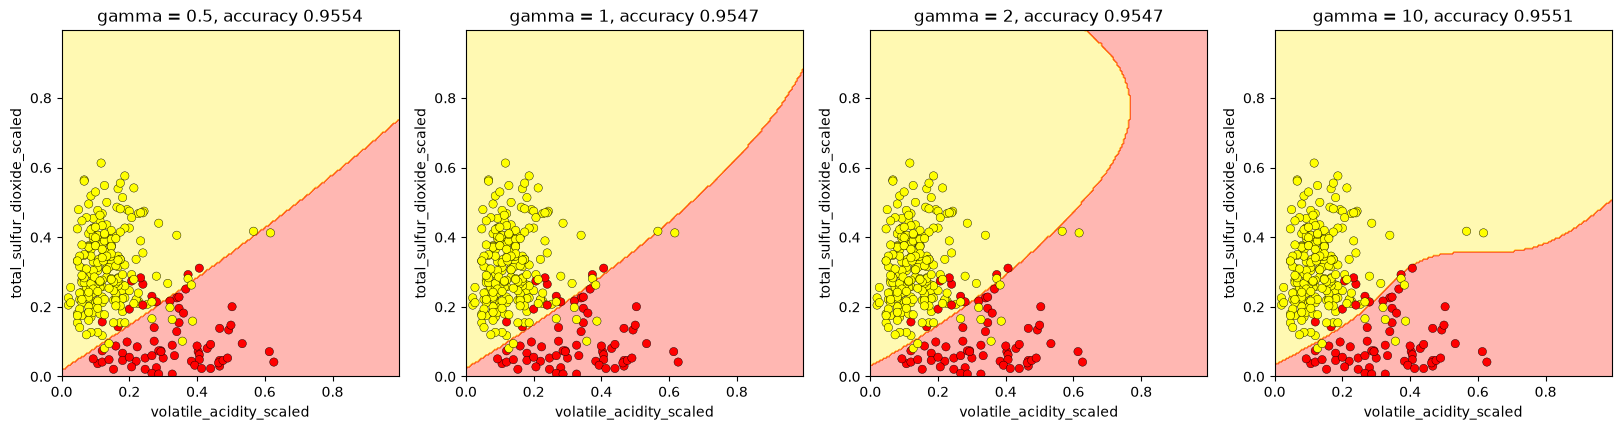

In [8]:
gammas = [.5, 1, 2, 10]

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, gamma in zip(axes, gammas):
    acc = plot_decision_boundary(SVC(kernel='rbf', gamma=gamma), X, y, ax)
    ax.set_title('gamma = ' + str(gamma) + ', accuracy ' + str(round(acc, 4)))
plt.show()

# чем больше gamma, тем меньше область влияния каждой точки, поэтому граница сильнее изгибается
# При gamma = 0.5 она почти прямая, как у LinearSVC, при gamma = 2 сильно загибается справа сверху, где точек почти нет,
# а при gamma = 10 изгибается вокруг групп точек около границы
# Accuracy почти не меняется (около 0.955): на двух признаках классы перекрываются, и граница меняется в основном там, где мало точек

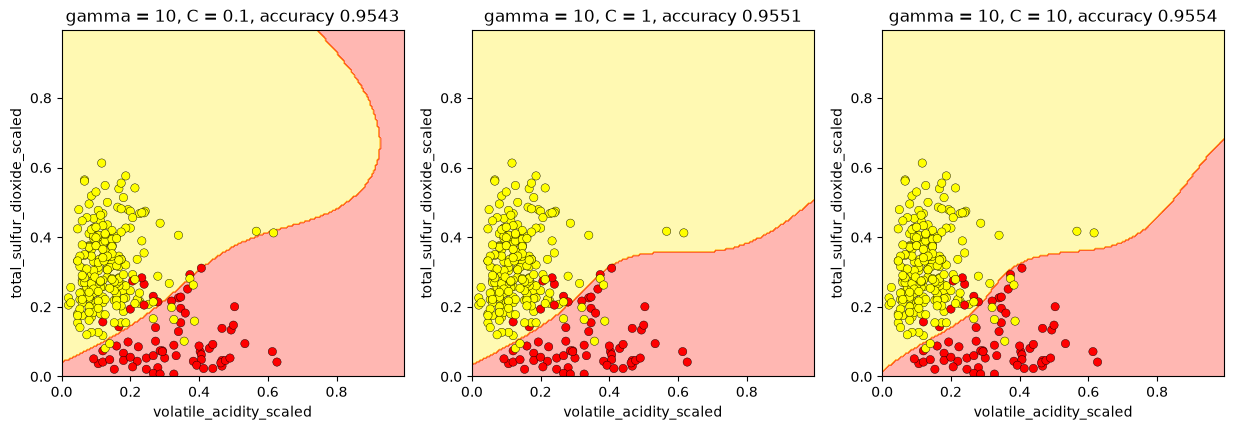

In [9]:
# gamma оставляем 10: при ней граница самая гибкая, и влияние C видно лучше всего
Cs = [.1, 1, 10]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, C in zip(axes, Cs):
    acc = plot_decision_boundary(SVC(kernel='rbf', gamma=10, C=C), X, y, ax)
    ax.set_title('gamma = 10, C = ' + str(C) + ', accuracy ' + str(round(acc, 4)))
plt.show()

# C это штраф за ошибки на train. При C = 0.1 модель разрешает больше ошибок, поэтому граница около точек плавнее,
# а в пустой области справа сверху снова сильно загибается. При C = 1 и C = 10 граница сильнее подстраивается под отдельные точки.
# Accuracy растет совсем немного (0.9543, 0.9551, 0.9554), значит большой C почти ничего не дает, а риск переобучения растет

## Вопрос 4

В этом вопросе мы сравним время установки между SVC и Nystroem с ядром rbf.  
<br><br>
Jupyter Notebooks предоставляет полезную магическую функцию **`%timeit`** которая выполняет строку и отпечатывает время, необходимое для установки. Если вы введете **`%timeit`** в начале ячейки, то она запустит всю ячейку и отобразит время выполнения.

* Повторно загрузите данные о качестве вина, если вы внесли изменения в оригинал.
* Создайте `y` из data.color и `X` из остальных столбцов.
* Используйте `%%timeit` чтобы получить время для настройки SVC с ядром rbf.
* Используйте `%%timeit` для получения времени для следующего: упорядочите данные с помощью Nystroem, а затем встроите SGD-классификатор.

Nystroem+SGD потребуется гораздо меньше времени для установки. Эта разница будет более выраженной, если набор данных был больше.

* Сделайте 5 копий X и свяжите их
* Сделайте 5 копий у и свяжите их
* Сравните время, необходимое для соответствия обоим методам выше.

In [10]:
# заново загружаем данные: y из color, X из всех остальных колонок
data = pd.read_csv(filepath)
y = (data['color'] == 'red').astype(int)
X = data.drop(columns='color')
print(X.shape)

# SVC импортирован в первой ячейке до patch_sklearn(), поэтому здесь обычный sklearn

(6497, 12)


In [11]:
%%timeit -n 1 -r 3
svc = SVC(kernel='rbf')
svc.fit(X, y)

173 ms ± 5.33 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


In [12]:
%%timeit -n 1 -r 3
# Nystroem строит приближенные признаки rbf ядра, а на них учится обычный линейный SGDClassifier
X_nys = Nystroem(kernel='rbf').fit_transform(X)
SGDClassifier().fit(X_nys, y)

127 ms ± 14.9 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


In [13]:
# 5 копий X и y подряд
X5 = pd.concat([X] * 5)
y5 = pd.concat([y] * 5)
print(X5.shape, y5.shape)

(32485, 12) (32485,)


In [14]:
%%timeit -n 1 -r 3
svc = SVC(kernel='rbf')
svc.fit(X5, y5)

4.31 s ± 234 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


In [15]:
%%timeit -n 1 -r 3
X5_nys = Nystroem(kernel='rbf').fit_transform(X5)
SGDClassifier().fit(X5_nys, y5)

# на исходных данных оба варианта учатся за доли секунды, и на таком маленьком наборе время сильно зависит от загрузки
# компьютера, от запуска к запуску оно меняется. А на 5 копиях разница уже явная: SVC учится несколько секунд,
# а Nystroem + SGD меньше секунды. SVC считает ядро для пар точек, поэтому его время растет быстрее, чем число строк.
# Nystroem считает ядро только со 100 выбранными точками (n_components по умолчанию), а дальше учится линейная модель,
# поэтому на больших данных так удобнее

509 ms ± 77.2 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)
